In [1]:
%%markdown

# Линейные методы

## Конфигурация окружения.



# Линейные методы

## Конфигурация окружения.


In [2]:
%cd %pwd/../../

Z:\.ITMO\sem_05\andan\labs\001\src


In [3]:
%%markdown

### Библиотеки

`sklearn` - только для загрузки и разбиения датасета, банальный `matplotlib` для вывода, отдельная математика из `scipy`.



### Библиотеки

`sklearn` - только для загрузки и разбиения датасета, банальный `matplotlib` для вывода, отдельная математика из `scipy`.


In [4]:
from pathlib import Path
from dataclasses import dataclass, field
from typing import Callable

import numpy as np
from scipy.special import expit

import matplotlib.pyplot as plt

from sklearn.datasets import load_svmlight_file
from sklearn.model_selection import train_test_split

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True

In [5]:
from IPython.display import display
_ = get_ipython().display_formatter.formatters['text/plain'].for_type(str, lambda string, pp, _: pp.text(string))

In [6]:
%%markdown

### Загрузка датасета

Я взял датасет с курса методов оптимизации, в нём немного признаков и он разумного размера.



### Загрузка датасета

Я взял датасет с курса методов оптимизации, в нём немного признаков и он разумного размера.


In [7]:
DATA_PATH = Path("./datasets/ijcnn1.txt.bz2")

@dataclass
class Dataset:
    X: np.ndarray
    y: np.ndarray

def load_dataset(path: Path) -> Dataset:
    X_sparse, y = load_svmlight_file(path)
    return Dataset(X_sparse.toarray().astype(np.float64), y.astype(np.float64))

DATA = load_dataset(DATA_PATH)

f"""Shape {DATA.X.shape}
classes {np.unique(DATA.y)}, class balance {np.bincount((DATA.y > 0).astype(int))}"""

Shape (49990, 22)
classes [-1.  1.], class balance [45137  4853]

In [8]:
%%markdown

### Разбиение датасета и проверка



### Разбиение датасета и проверка


In [9]:
RANDOM_STATE: int = 30

def split(test_size: float, *, data: Dataset = DATA, seed: int = RANDOM_STATE) -> tuple[Dataset, Dataset]:
    from sklearn.model_selection import train_test_split

    X_train, X_test, y_train, y_test = train_test_split(
        data.X, data.y, test_size=test_size, stratify=data.y, random_state=seed,
    )

    mu = X_train.mean(axis=0)
    sigma = X_train.std(axis=0)
    sigma[sigma == 0] = 1.0

    X_train = (X_train - mu) / sigma
    X_test = (X_test - mu) / sigma

    return Dataset(X_train, y_train), Dataset(X_test, y_test)

train, test = split(0.2)

f"""Train:
  Shape {train.X.shape}, class balance {np.bincount((train.y > 0).astype(int))}
Test:
  Shape {test.X.shape}, class balance {np.bincount((test.y > 0).astype(int))}
"""

Train:
  Shape (39992, 22), class balance [36110  3882]
Test:
  Shape (9998, 22), class balance [9027  971]


In [10]:
%%markdown

### Функции качества/ошибки

Банальное количество совпадений как точность.



### Функции качества/ошибки

Банальное количество совпадений как точность.


In [11]:
def accuracy(y_true: np.ndarray, y_score: np.ndarray) -> float:
    return float(np.mean(np.sign(y_score) == y_true))

def error(y_true: np.ndarray, y_score: np.ndarray) -> float:
    return 1.0 - accuracy(y_true, y_score)

In [12]:
%%markdown

## Алгоритмы

### Линейная регрессия в матричном виде



## Алгоритмы

### Линейная регрессия в матричном виде


In [13]:
class LinearRegression:
    def __init__(self, alpha: float = 1.0, penalize_intercept: bool = False):
        self.alpha = alpha
        self.penalize_intercept = penalize_intercept
        self.coef_: np.ndarray | None = None
        self.intercept_: float | None = None

    def fit(self, data: Dataset) -> None:
        X, y = data.X, data.y
        n, d = X.shape
        X_aug = np.hstack([np.ones((n, 1)), X])

        A = X_aug.T @ X_aug
        b = X_aug.T @ y

        penalty = self.alpha * np.eye(d + 1)
        if not self.penalize_intercept:
            penalty[0, 0] = 0.0

        theta = np.linalg.solve(A + penalty, b)
        self.intercept_ = float(theta[0])
        self.coef_ = theta[1:]

    def predict(self, X: np.ndarray) -> np.ndarray:
        return X @ self.coef_ + self.intercept_


class LinearRegressionClassifier:
    def __init__(self, alpha: float = 1.0, penalize_intercept: bool = False):
        self._reg = LinearRegression(alpha=alpha, penalize_intercept=penalize_intercept)

    def fit(self, data: Dataset) -> None:
        self._reg.fit(data)

    def decision_function(self, X: np.ndarray) -> np.ndarray:
        return self._reg.predict(X)

    def predict(self, X: np.ndarray) -> np.ndarray:
        return np.sign(self.decision_function(X))

In [14]:
def verify():
    from sklearn.linear_model import Ridge

    rng = np.random.default_rng(0)
    X = rng.normal(size=(200, 5))
    y = X @ np.array([1.0, -2.0, 0.5, 0.0, 3.0]) + 0.4 + rng.normal(0, 0.1, 200)
    synth = Dataset(X, y)
    
    for alpha in [0.01, 1.0, 100.0]:
        ours = LinearRegression(alpha=alpha)
        ours.fit(synth)
        sk = Ridge(alpha=alpha, fit_intercept=True).fit(X, y)

        coeff_distance = np.max(np.abs(np.r_[ours.intercept_, ours.coef_] - np.r_[sk.intercept_, sk.coef_]))
        print(f"alpha = {alpha}: max|Δ| = {coeff_distance:.2e}")

verify()

alpha = 0.01: max|Δ| = 1.33e-15
alpha = 1.0: max|Δ| = 4.44e-16
alpha = 100.0: max|Δ| = 6.66e-16


In [15]:
def test(alpha, test_size):
    train, test = split(test_size)

    clf = LinearRegressionClassifier(alpha)
    clf.fit(train)

    result_train = clf.decision_function(train.X)
    result_test = clf.decision_function(test.X)

    print(f"alpha = {alpha}, test = {test_size:.0%}: train error = {error(train.y, result_train):.3%}, test error = {error(test.y, result_test):.3%}")

for alpha in [0.0001, 0.01, 1.0, 100.0, 10000.0]:
    for test_size in [0.1, 0.2, 0.3]:
        test(alpha, test_size)

alpha = 0.0001, test = 10%: train error = 8.451%, test error = 8.322%
alpha = 0.0001, test = 20%: train error = 8.472%, test error = 8.242%
alpha = 0.0001, test = 30%: train error = 8.476%, test error = 8.322%
alpha = 0.01, test = 10%: train error = 8.451%, test error = 8.322%
alpha = 0.01, test = 20%: train error = 8.472%, test error = 8.242%
alpha = 0.01, test = 30%: train error = 8.476%, test error = 8.322%
alpha = 1.0, test = 10%: train error = 8.451%, test error = 8.322%
alpha = 1.0, test = 20%: train error = 8.472%, test error = 8.242%
alpha = 1.0, test = 30%: train error = 8.476%, test error = 8.322%
alpha = 100.0, test = 10%: train error = 8.446%, test error = 8.362%
alpha = 100.0, test = 20%: train error = 8.477%, test error = 8.282%
alpha = 100.0, test = 30%: train error = 8.490%, test error = 8.368%
alpha = 10000.0, test = 10%: train error = 9.257%, test error = 9.242%
alpha = 10000.0, test = 20%: train error = 9.317%, test error = 9.212%
alpha = 10000.0, test = 30%: train e

In [16]:
%%markdown

### Линейная классификация на основе градиентного спуска



### Линейная классификация на основе градиентного спуска


In [17]:
LossFn = Callable[[np.ndarray], np.ndarray]
Risk = tuple[LossFn, LossFn]

LOGISTIC: Risk = (
    lambda M: np.logaddexp(0.0, -M),
    lambda M: -expit(-M),
)
HINGE: Risk = (
    lambda M: np.maximum(0.0, 1.0 - M),
    lambda M: -np.where(M < 1.0, 1.0, 0.0),
)
SQR_HINGE: Risk = (
    lambda M: np.maximum(0.0, 1.0 - M) ** 2,
    lambda M: -2.0 * np.where(M < 1.0, 1.0 - M, 0.0),
)

In [18]:
@dataclass
class GDParams:
    learning_rate: float = 0.1
    lambda1: float = 0.0
    lambda2: float = 0.0
    max_iter: int = 1000
    tol: float = 1e-7


@dataclass
class History:
    empirical_risk: list[float] = field(default_factory=list)
    objective: list[float] = field(default_factory=list)

@dataclass
class GDParams:
    learning_rate: float = 0.1
    lambda1: float = 0.0
    lambda2: float = 0.0
    max_iter: int = 1000
    tol: float = 1e-7


@dataclass
class History:
    empirical_risk: list[float] = field(default_factory=list)
    objective: list[float] = field(default_factory=list)


class GDClassifier:
    def __init__(self, loss: Risk, params: GDParams | None = None):
        self.loss = loss
        self.params = params or GDParams()
        self.coef_: np.ndarray | None = None
        self.intercept_: float = 0.0
        self.history_: History = History()

    def _gradient(self, X, y, w, b):
        loss_fn, grad_fn = self.loss
        M = y * (X @ w + b)
        emp = loss_fn(M).mean()
        reg = self.params.lambda1 * np.abs(w).sum() + self.params.lambda2 * (w @ w)
        dz = grad_fn(M) * y
        grad_w = (X.T @ dz) / len(y) + self.params.lambda1 * np.sign(w) + 2.0 * self.params.lambda2 * w
        grad_b = dz.mean()
        return emp, reg, grad_w, grad_b

    def fit_step(self, X, y, w, b):
        emp, reg, grad_w, grad_b = self._gradient(X, y, w, b)
        w = w - self.params.learning_rate * grad_w
        b = b - self.params.learning_rate * grad_b
        return w, b, emp, reg

    def fit(self, data: Dataset):
        X, y = data.X, data.y
        w = np.zeros(X.shape[1])
        b = 0.0
        history = History()
        prev_obj = np.inf

        for _ in range(self.params.max_iter):
            w, b, emp, reg = self.fit_step(X, y, w, b)
            obj = emp + reg
            history.empirical_risk.append(emp)
            history.objective.append(obj)
            if abs(prev_obj - obj) < self.params.tol:
                break
            prev_obj = obj

        self.coef_ = w
        self.intercept_ = b
        self.history_ = history

    def decision_function(self, X: np.ndarray) -> np.ndarray:
        return X @ self.coef_ + self.intercept_

    def predict(self, X: np.ndarray) -> np.ndarray:
        return np.where(self.decision_function(X) >= 0.0, 1.0, -1.0)

In [19]:
def test(loss_name, loss, lr, test_size):
    train, test = split(test_size)

    clf = GDClassifier(loss, GDParams(learning_rate=lr, max_iter=1000))
    clf.fit(train)

    result_train = clf.decision_function(train.X)
    result_test = clf.decision_function(test.X)

    print(f"loss = {loss_name}, lr = {lr}, test = {test_size:.0%}: iters = {len(clf.history_.objective):4d}, "
          f"train error = {error(train.y, result_train):.3%}, test error = {error(test.y, result_test):.3%}")

for loss_name, loss in [("logistic", LOGISTIC), ("hinge", HINGE), ("sqr_hinge", SQR_HINGE)]:
    for lr in [0.1, 0.5, 1.0]:
        test(loss_name, loss, lr, 0.2)

loss = logistic, lr = 0.1, test = 20%: iters = 1000, train error = 7.854%, test error = 7.682%
loss = logistic, lr = 0.5, test = 20%: iters = 1000, train error = 7.509%, test error = 7.592%
loss = logistic, lr = 1.0, test = 20%: iters =  682, train error = 7.494%, test error = 7.562%
loss = hinge, lr = 0.1, test = 20%: iters = 1000, train error = 7.959%, test error = 7.832%
loss = hinge, lr = 0.5, test = 20%: iters =  640, train error = 7.529%, test error = 7.441%
loss = hinge, lr = 1.0, test = 20%: iters =  351, train error = 7.517%, test error = 7.431%
loss = sqr_hinge, lr = 0.1, test = 20%: iters =  489, train error = 7.704%, test error = 7.532%
loss = sqr_hinge, lr = 0.5, test = 20%: iters =  118, train error = 7.684%, test error = 7.562%
loss = sqr_hinge, lr = 1.0, test = 20%: iters = 1000, train error = 7.917%, test error = 7.802%


In [20]:
%%markdown

## Задания

### Подбор гиперпараметров

Для регрессии, альфа равная 1.0 выглядит нормально.

Для классификации, эмпирический риск hinge с learning rate равным 1.0 выглядит наиболее оптимально, а для L1/L2 будет отдельное задание.

### Кривая эмпирического риска



## Задания

### Подбор гиперпараметров

Для регрессии, альфа равная 1.0 выглядит нормально.

Для классификации, эмпирический риск hinge с learning rate равным 1.0 выглядит наиболее оптимально, а для L1/L2 будет отдельное задание.

### Кривая эмпирического риска


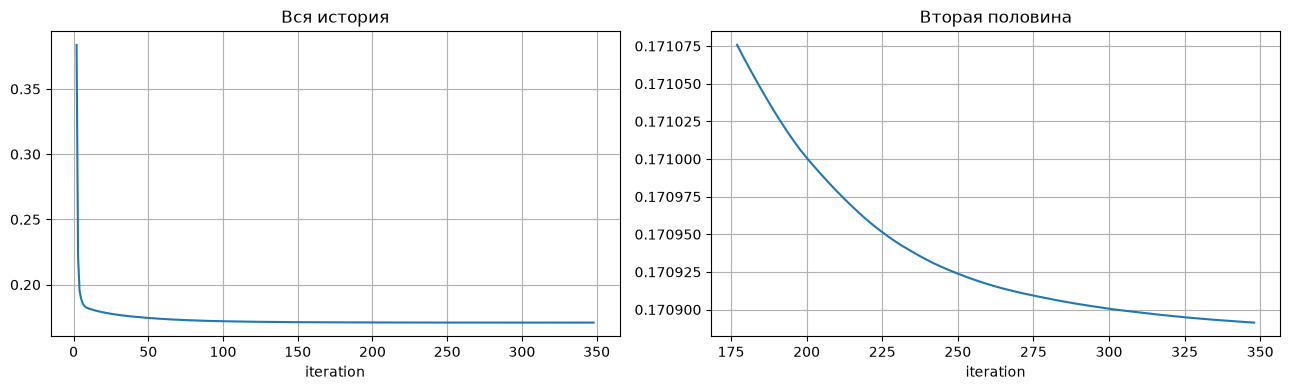

In [21]:
AVERAGE_WINDOW_EXTENT = 2

def moving_average(x: np.ndarray) -> np.ndarray:
    window = AVERAGE_WINDOW_EXTENT * 2 + 1

    kernel = np.ones(window) / window
    return np.convolve(x, kernel, mode="valid")

def risk_curve():
    train, test = split(0.2)
    
    clf = GDClassifier(HINGE, GDParams(learning_rate=1.0, max_iter=1000))
    clf.fit(train)
    
    risk = np.asarray(clf.history_.empirical_risk)
    smoothed = moving_average(risk)
    half = len(risk) // 2
    
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    off = AVERAGE_WINDOW_EXTENT
    axes[0].plot(np.arange(off, len(risk) - off), smoothed)
    axes[0].set_xlabel("iteration")
    axes[0].set_title("Вся история")
    
    axes[1].plot(np.arange(half + off, len(risk) - off), smoothed[half:])
    axes[1].set_xlabel("iteration")
    axes[1].set_title("Вторая половина")
    
    plt.tight_layout()
    plt.show()

risk_curve()

In [22]:
%%markdown

### Кривая функции ошибки



### Кривая функции ошибки
